# GROUP_02 — Hip fracture among adult women (W2)
Source: GRD Fonasa parquet, 2019–2024. This notebook corrects issues flagged in C1 feedback
(hardcoded path, undefined-before-use variables, commune-year check mismatch, male age-bin bug)
and adds the W2 requirements: upstream provenance check, leakage review, train/test split,
and one training-only transformation.

**Library requirements:** pandas, numpy, matplotlib, pyarrow (or fastparquet, to read the parquet).
Install with `pip install pandas numpy matplotlib pyarrow`.

**Run instructions:** place `grd_procesado.parquet` in `./data/` relative to this notebook, then
Restart Kernel and Run All, top to bottom, before submission.

In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#DATA_PATH = Path('./data/grd_procesado.parquet')  # project-relative, not a personal path
DATA_PATH = Path('/Users/maria/Documents/Business Intehlligence/W1/grd_procesado.parquet')

## 1. Load data and initial inspection

In [7]:
df = pd.read_parquet(DATA_PATH)  # original, never modified downstream
print('Shape:', df.shape)
df.head()

Shape: (367895, 52)


,COD_ESTABLECIMIENTO,CIP_ENCRIPTADO,SEXO,FECHA_NACIMIENTO,PROVINCIA,COMUNA_REGISTRADA,PREVISION,SERVICIO_SALUD,TIPO_PROCEDENCIA,TIPO_INGRESO,...,CAMAS_CRITICAS,POB_MULT_ESTAB,COMUNA_CON_ESTAB_AC,FALLECIDO,CRITICAS_PROP,CAMAS_COMUNA,CRITICAS_COMUNA,CAMAS_1000HAB,CRITICAS_1000HAB,TASA_MORTALIDAD_COMUNA
0,118100,467373,HOMBRE,1969-09-10,CONCEPCION,SAN PEDRO DE LA PAZ,FONASA INSTITUCIONAL - (MAI) B,CONCEPCIÓN,SERVICIO EMERGENCIA (DOMICILIO),URGENCIA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963
1,118100,562854,HOMBRE,1956-02-07,CONCEPCION,CORONEL,FONASA INSTITUCIONAL - (MAI) A,CONCEPCIÓN,SERVICIO EMERGENCIA (DOMICILIO),URGENCIA,...,113,0.090303,1,0,0.128118,882,113,3.717488,0.476277,0.117963
2,118100,199980,MUJER,1960-02-28,CONCEPCION,SAN PEDRO DE LA PAZ,FONASA INSTITUCIONAL - (MAI) A,CONCEPCIÓN,APS CONSULTORIO (CESFAM),URGENCIA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963
3,118100,857926,MUJER,1933-01-12,CONCEPCION,CHIGUAYANTE,FONASA INSTITUCIONAL - (MAI) D,CONCEPCIÓN,"OTRAS INSTITUCIONES SALUD (CLÍNICAS PRIVADAS, ...",URGENCIA,...,113,0.090303,0,1,0.128118,882,113,3.717488,0.476277,0.117963
4,118100,284629,HOMBRE,1951-05-03,CURICO,TENO,FONASA INSTITUCIONAL - (MAI) C,DEL MAULE,"CENTRO ESPECIALIDADES (CDT, CRS, CONSULTORIO A...",PROGRAMADA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963


In [8]:
print('Nulls per column:')
print(df.isnull().sum())

Nulls per column:
COD_ESTABLECIMIENTO          0
CIP_ENCRIPTADO               0
SEXO                         0
FECHA_NACIMIENTO             0
PROVINCIA                    0
COMUNA_REGISTRADA            0
PREVISION                    0
SERVICIO_SALUD               0
TIPO_PROCEDENCIA             0
TIPO_INGRESO                 0
FECHA_INGRESO                0
FECHAALTA                    0
TIPOALTA                     0
DIAGNOSTICO1                 0
DIAGNOSTICO2                 9
DIAGNOSTICO3              4920
PROCEDIMIENTO1             127
PROCEDIMIENTO2            2329
IR_29301_COD_GRD             0
IR_29301_PESO                0
IR_29301_SEVERIDAD           0
IR_29301_MORTALIDAD          0
YEAR                         0
EDAD                         0
DIAS_ESTANCIA                0
N_COMORBILIDADES             0
N_PROCEDIMIENTOS             0
INDICE_CHARLSON              0
DESCRIPCION                  0
SECCION                      0
COD_REGION                   0
REGION               

In [9]:
print(df['COMPLEJIDAD_ESTAB'].value_counts(dropna=False))
print()
print(df['SEXO'].value_counts(dropna=False))
print()
print(df['EDAD'].describe())
print()
print(df['YEAR'].value_counts().sort_index())

COMPLEJIDAD_ESTAB
Alta Complejidad       358743
Mediana Complejidad      9152
Baja Complejidad            0
No Aplica                   0
Pendiente                   0
Name: count, dtype: int64

SEXO
HOMBRE         213422
MUJER          154431
DESCONOCIDO        42
Name: count, dtype: int64

count    367895.000000
mean         50.987017
std          26.229025
min           0.000000
25%          34.500000
50%          58.400000
75%          70.800000
max         108.200000
Name: EDAD, dtype: float64

YEAR
2019    50135
2020    54370
2021    67748
2022    61547
2023    66717
2024    67378
Name: count, dtype: int64


**Coverage check (C1 feedback: verify the 'high complexity only' claim).**
State plainly below what `COMPLEJIDAD_ESTAB` actually contains, and correct the report if it
includes medium-complexity establishments.

In [10]:
# Fill in after running the value_counts above:
# e.g. "COMPLEJIDAD_ESTAB contains: {Alta Complejidad: X, Media Complejidad: Y}.
#       The dataset is NOT high-complexity-only; the report's coverage claim must be corrected."


## 2. Upstream data provenance
The parquet arrives already selected/enriched (joined commune-level fields, pre-filtered by
complexity). C1 feedback noted that excluding extra columns cannot undo an earlier change in
row count. This section states plainly what is and is not traceable about those upstream steps.

In [11]:
# What we can verify: the file's current row count and the fields it already carries.
print('Total rows as delivered:', len(df))
print('Columns already present (pre-joined/derived):', list(df.columns))

# What we CANNOT verify from this file alone: how many rows existed before any upstream
# filtering/joining, or whether that upstream step duplicated or dropped episodes.
# This is stated here explicitly rather than assumed away.

Total rows as delivered: 367895
Columns already present (pre-joined/derived): ['COD_ESTABLECIMIENTO', 'CIP_ENCRIPTADO', 'SEXO', 'FECHA_NACIMIENTO', 'PROVINCIA', 'COMUNA_REGISTRADA', 'PREVISION', 'SERVICIO_SALUD', 'TIPO_PROCEDENCIA', 'TIPO_INGRESO', 'FECHA_INGRESO', 'FECHAALTA', 'TIPOALTA', 'DIAGNOSTICO1', 'DIAGNOSTICO2', 'DIAGNOSTICO3', 'PROCEDIMIENTO1', 'PROCEDIMIENTO2', 'IR_29301_COD_GRD', 'IR_29301_PESO', 'IR_29301_SEVERIDAD', 'IR_29301_MORTALIDAD', 'YEAR', 'EDAD', 'DIAS_ESTANCIA', 'N_COMORBILIDADES', 'N_PROCEDIMIENTOS', 'INDICE_CHARLSON', 'DESCRIPCION', 'SECCION', 'COD_REGION', 'REGION', 'ESTABLECIMIENTO', 'COD_COMUNA', 'COMUNA_ESTAB', 'LATITUD', 'LONGITUD', 'PRESTADOR', 'COMPLEJIDAD_ESTAB', 'POB_COMUNA', 'POB_REGION', 'CAMAS_TOTALES', 'CAMAS_CRITICAS', 'POB_MULT_ESTAB', 'COMUNA_CON_ESTAB_AC', 'FALLECIDO', 'CRITICAS_PROP', 'CAMAS_COMUNA', 'CRITICAS_COMUNA', 'CAMAS_1000HAB', 'CRITICAS_1000HAB', 'TASA_MORTALIDAD_COMUNA']


**2024 completeness check** (pending item from C1 feedback — confirm the last year isn't
truncated before using it in year-over-year comparisons).

In [15]:
df['FECHAALTA'] = pd.to_datetime(df['FECHAALTA'], errors='coerce')  # adjust column name if different
monthly = df['FECHAALTA'].dt.to_period('M').value_counts().sort_index()
print(monthly.tail(18))

FECHAALTA
2023-07    5899
2023-08    5927
2023-09    5447
2023-10    5666
2023-11    5608
2023-12    5493
2024-01    5751
2024-02    5434
2024-03    5623
2024-04    5920
2024-05    6141
2024-06    5855
2024-07    6308
2024-08    6343
2024-09    5615
2024-10    6463
2024-11    5880
2024-12    6004
Freq: M, Name: count, dtype: int64


## 3. Data quality checks
Four distinct checks: duplicates, missing values, invalid values, recorded periods.

### 3.1 Duplicate records

In [16]:
dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
print('Rows involved in duplication:', dups.shape[0])
print('Exact duplicate rows (duplicated()):', df.duplicated().sum())
print(f"Percentage: {df.duplicated().sum()/len(df)*100:.3f}%")

Rows involved in duplication: 210
Exact duplicate rows (duplicated()): 105
Percentage: 0.029%


In [17]:
# Which year the duplicates concentrate in
df.groupby('YEAR').apply(lambda x: x.duplicated().sum())

YEAR
2019      2
2020    103
2021      0
2022      0
2023      0
2024      0
dtype: int64

In [18]:
# Inspect a sample: same diagnosis/age/sex/year confirms these are not distinct episodes
dups[['CIP_ENCRIPTADO','DESCRIPCION','EDAD','SEXO','YEAR']].head(20)

,CIP_ENCRIPTADO,DESCRIPCION,EDAD,SEXO,YEAR
82540,612841,"COVID-19, virus identificado",63.5,MUJER,2020
83545,612841,"COVID-19, virus identificado",63.5,MUJER,2020
48828,233609,"Traumatismo del intestino delgado, con herida ...",14.8,HOMBRE,2020
90463,233609,"Traumatismo del intestino delgado, con herida ...",14.8,HOMBRE,2020
68585,397419,"Fractura del cuello de fémur, cerrada",89.6,HOMBRE,2020
72968,397419,"Fractura del cuello de fémur, cerrada",89.6,HOMBRE,2020
47221,931293,"Hemorragia intracerebral en hemisferio, cortical",53.5,HOMBRE,2020
73457,931293,"Hemorragia intracerebral en hemisferio, cortical",53.5,HOMBRE,2020
48473,1332239,"Esclerosis sistémica, no especificada",41.0,MUJER,2020
85805,1332239,"Esclerosis sistémica, no especificada",41.0,MUJER,2020


**Rule:** a row is a duplicate if every field matches another row exactly.
**Result:** see counts above (105 rows, ~0.03%, concentrated in 2020).
**Meaning:** matching derived/joined fields rules out genuine re-admission; most likely a 2020
reprocessing artifact.
**Action:** drop exact duplicates; keep all other rows unchanged.

In [19]:
df_clean = df.drop_duplicates().copy()
print('Rows before:', len(df), '| Rows after:', len(df_clean))

Rows before: 367895 | Rows after: 367790


### 3.2 Missing values (beyond the isnull() count above)

In [20]:
# Placeholder codes that hide missingness without appearing as NaN
for c in ['CIP_ENCRIPTADO', 'DIAGNOSTICO1', 'SEXO']:
    if c in df_clean.columns:
        flagged = df_clean[c].isin(['SIN INFORMACIÓN', 'DESCONOCIDO'])
        print(c, '-> placeholder count:', flagged.sum())

CIP_ENCRIPTADO -> placeholder count: 654
DIAGNOSTICO1 -> placeholder count: 0
SEXO -> placeholder count: 42


### 3.3 Invalid values

In [21]:
invalid_age = df_clean[(df_clean['EDAD'] < 0) | (df_clean['EDAD'] > 110)]
print('Rows with EDAD outside [0, 110]:', len(invalid_age))

Rows with EDAD outside [0, 110]: 0


### 3.4 Recorded periods

In [22]:
number_of_establishments_by_year = (
    df_clean.groupby('YEAR')['ESTABLECIMIENTO']
    .nunique()
    .reset_index()
    .rename(columns={'ESTABLECIMIENTO': 'num_establishments'})
)
number_of_establishments_by_year

,YEAR,num_establishments
0,2019,65
1,2020,65
2,2021,65
3,2022,68
4,2023,70
5,2024,72


## 4. Variable dictionary (key fields used below)

| Field | Meaning | Unit / codes | Missing means |
|---|---|---|---|
| `SEXO` | Patient sex | MUJER / HOMBRE | not observed in this data |
| `EDAD` | Age at admission | years | n/a (0% missing) |
| `DIAGNOSTICO1` | Primary diagnosis, ICD-10 | code, e.g. S72.00 | n/a |
| `DESCRIPCION` | Primary diagnosis, free text | text | n/a |
| `DIAS_ESTANCIA` | Length of stay | days | n/a |
| `FALLECIDO` | Died during this episode | 0/1 | not observed |
| `TIPOALTA` | Discharge destination | category | n/a |
| `IR_29301_SEVERIDAD` | GRD severity category | ordinal | n/a |
| `INDICE_CHARLSON` | Comorbidity index | numeric | n/a |
| `N_COMORBILIDADES` | Comorbidity count | integer | n/a |
| `COMUNA_ESTAB` | Hospital's commune | text | n/a |
| `COMUNA_REGISTRADA` | Patient's registered commune | text | n/a |
| `CIP_ENCRIPTADO` | Encrypted patient identifier | hash | placeholder values possible (see 3.2) |

*(Adjust row-count/placeholder notes above once the notebook is run on the real file.)*

## 5. Build the analysis population
All downstream cells use `mujeres` (adult women) and `hip` (hip-fracture subset). Both are
defined here, once, before any cell that uses them (fixes the C1 execution-order issue).

In [23]:
bins   = [18, 30, 45, 60, 75, 90, 111]
labels = ['18-29', '30-44', '45-59', '60-74', '75-89', '90+']
YEARS  = range(2019, 2025)

mujeres = df_clean[(df_clean['SEXO'] == 'MUJER') &
                    (df_clean['EDAD'] >= 18) &
                    (df_clean['YEAR'].isin(YEARS))].copy()
mujeres['GRUPO_ETARIO'] = pd.cut(mujeres['EDAD'], bins=bins, labels=labels, right=False)

hip_codes = ['Fractura del cuello de fémur, cerrada', 'Fractura pertrocanteriana, cerrada']
hip = mujeres[mujeres['DESCRIPCION'].isin(hip_codes)].copy()

hombres = df_clean[(df_clean['SEXO'] == 'HOMBRE') &
                    (df_clean['EDAD'] >= 18) &
                    (df_clean['YEAR'].isin(YEARS))].copy()
hip_m = hombres[hombres['DESCRIPCION'].isin(hip_codes)].copy()

print('mujeres:', len(mujeres), '| hip (women):', len(hip), '| hip (men):', len(hip_m))

mujeres: 127220 | hip (women): 4361 | hip (men): 1677


### 5.1 Validate the hip-fracture cohort against ICD-10 codes

In [24]:
codigos_reales = mujeres.loc[mujeres['DESCRIPCION'].isin(hip_codes), 'DIAGNOSTICO1'].unique()
print('ICD-10 codes found for these DESCRIPCION values:', codigos_reales)

hip2 = mujeres[mujeres['DIAGNOSTICO1'].isin(codigos_reales)].copy()
print('hip (by description):', len(hip), '| hip2 (by ICD-10 code):', len(hip2))
print('Cohorts match:', set(hip['CIP_ENCRIPTADO']) == set(hip2['CIP_ENCRIPTADO']))

ICD-10 codes found for these DESCRIPCION values: <StringArray>
['S72.00', 'S72.10']
Length: 2, dtype: string
hip (by description): 4361 | hip2 (by ICD-10 code): 4361
Cohorts match: True


### 5.2 Filter waterfall (row counts at each stage)

In [25]:
waterfall = pd.DataFrame({
    'step': ['Full dataset', 'Deduplicated', 'Adult women, study years', 'Hip fracture subset'],
    'rows': [len(df), len(df_clean), len(mujeres), len(hip)]
})
waterfall['pct_of_original'] = waterfall['rows'] / len(df) * 100
waterfall

,step,rows,pct_of_original
0,Full dataset,367895,100.000000
1,Deduplicated,367790,99.971459
2,"Adult women, study years",127220,34.580519
3,Hip fracture subset,4361,1.185393


## 6. Data checks and limits (Five Cs)

### 6.1 Conformed — commune-level fields (CORRECTED to match the report's description)
C1 feedback: the report described a commune-**year** check, but the code only grouped by
commune. Fixed below.

In [26]:
key_by_estab      = df.groupby('COMUNA_ESTAB')['POB_COMUNA'].nunique().max()
key_by_estab_year  = df.groupby(['COMUNA_ESTAB', 'YEAR'])['POB_COMUNA'].nunique().max()
key_by_reg         = df.groupby('COMUNA_REGISTRADA')['POB_COMUNA'].nunique().max()

print('Keyed on COMUNA_ESTAB alone:', key_by_estab)
print('Keyed on (COMUNA_ESTAB, YEAR):', key_by_estab_year)   # should be 1 if population is annual
print('Keyed on COMUNA_REGISTRADA:', key_by_reg)

pct_diff = (df['COMUNA_REGISTRADA'] != df['COMUNA_ESTAB']).mean() * 100
print(f'Registered != establishment commune: {pct_diff:.1f}%')

Keyed on COMUNA_ESTAB alone: 6
Keyed on (COMUNA_ESTAB, YEAR): 1
Keyed on COMUNA_REGISTRADA: 200
Registered != establishment commune: 57.2%


/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_46209/4169676358.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  key_by_reg         = df.groupby('COMUNA_REGISTRADA')['POB_COMUNA'].nunique().max()


### 6.2 Consistent — severity coding stability by year
Note: similar distributions are *consistent with* unchanged coding, not proof of it (C1 feedback).

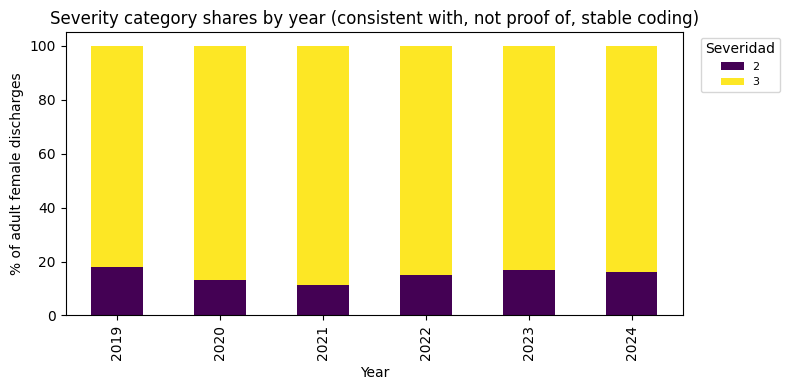

In [27]:
sev_anual = (mujeres.groupby(['YEAR', 'IR_29301_SEVERIDAD'], observed=True)
             .size().unstack().apply(lambda r: r / r.sum() * 100, axis=1))

fig, ax = plt.subplots(figsize=(8, 4))
sev_anual.plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
ax.set_ylabel('% of adult female discharges')
ax.set_xlabel('Year')
ax.set_title('Severity category shares by year (consistent with, not proof of, stable coding)')
ax.legend(title='Severidad', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### 6.3 Establishment growth, normalized

In [28]:
anual = df_clean[df_clean.YEAR.isin(YEARS)].groupby('YEAR').agg(
    total=('SEXO', 'size'),
    mujeres=('SEXO', lambda s: (s == 'MUJER').sum())
)
n_estab = number_of_establishments_by_year.set_index('YEAR')['num_establishments']
anual['discharges_per_estab'] = anual['mujeres'] / n_estab
anual

,total,mujeres,discharges_per_estab
YEAR,,,
2019,50133,21612,332.492308
2020,54267,21771,334.938462
2021,67748,27970,430.307692
2022,61547,26022,382.676471
2023,66717,28114,401.628571
2024,67378,28902,401.416667


## 7. Exploratory analysis

### 7.1 Distribution — length of stay, adult women

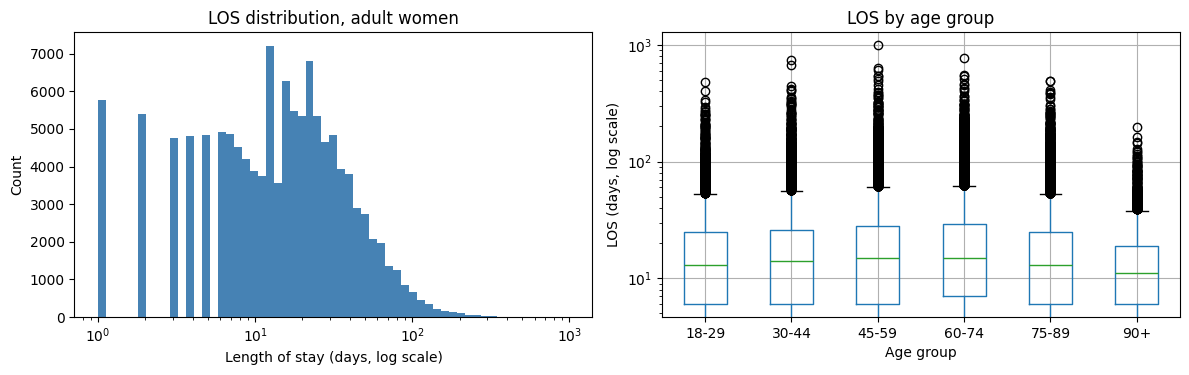

In [29]:
los_pos = mujeres.loc[mujeres['DIAS_ESTANCIA'] > 0, 'DIAS_ESTANCIA']
log_bins = np.logspace(np.log10(los_pos.min()), np.log10(los_pos.max()), 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(los_pos, bins=log_bins, color='steelblue')
axes[0].set_xscale('log')
axes[0].set_xlabel('Length of stay (days, log scale)')
axes[0].set_ylabel('Count')
axes[0].set_title('LOS distribution, adult women')

mujeres.boxplot(column='DIAS_ESTANCIA', by='GRUPO_ETARIO', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_xlabel('Age group')
axes[1].set_ylabel('LOS (days, log scale)')
axes[1].set_title('LOS by age group')
plt.suptitle('')
plt.tight_layout()
plt.show()

### 7.2 Comparison — discharge destination by age group AND by year (corrected scope)
C1 feedback: the claim that home hospitalization *increased over time* and *caused* shorter
stays went beyond what was shown. This cell tests the time dimension directly instead of
assuming it.

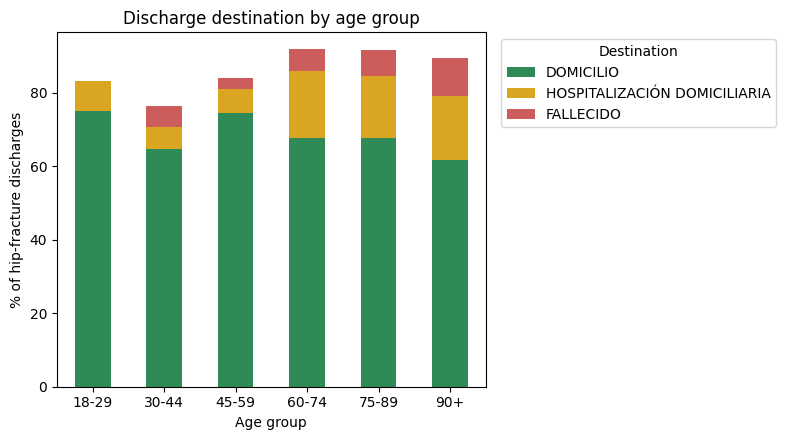

In [30]:
dest_by_age = pd.crosstab(hip['GRUPO_ETARIO'], hip['TIPOALTA'], normalize='index') * 100
keep = ['DOMICILIO', 'HOSPITALIZACIÓN DOMICILIARIA', 'FALLECIDO']

fig, ax = plt.subplots(figsize=(8, 4.5))
dest_by_age[keep].plot(kind='bar', stacked=True, ax=ax, color=['seagreen', 'goldenrod', 'indianred'])
ax.set_ylabel('% of hip-fracture discharges')
ax.set_xlabel('Age group')
ax.set_title('Discharge destination by age group')
ax.legend(title='Destination', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

TIPOALTA  DOMICILIO  HOSPITALIZACIÓN DOMICILIARIA  FALLECIDO
YEAR                                                        
2019      75.233645                      7.009346   8.411215
2020      65.975104                     10.788382  13.278008
2021      65.000000                     16.774194   9.032258
2022      67.833698                     16.192560   7.111597
2023      64.712042                     19.685864   6.806283
2024      63.201663                     23.284823   4.885655


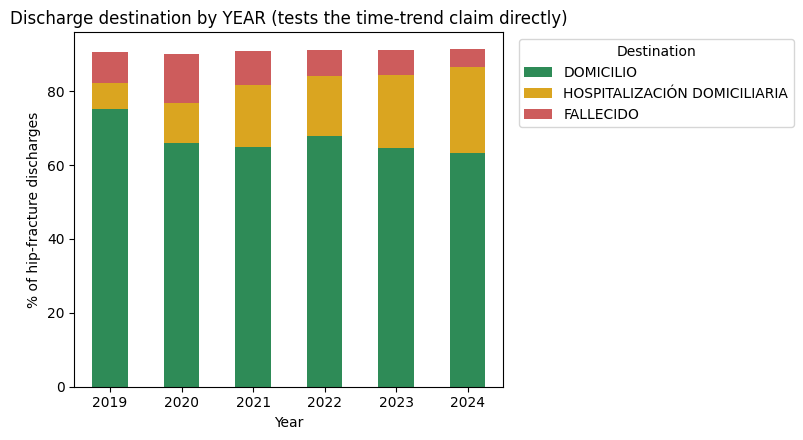

TIPOALTA                                       FALLECIDO
ALTA VOLUNTARIA                                0            18.0
DERIVACIÓN A OTROS CENTROS (CÁRCEL, HOGAR DE   0            12.0
DERIVACIÓN INST. PRIVADA (COMPRA DE SERVICIOS  0            17.0
DERIVACIÓN INST. PRIVADA (VOLUNTARIO)          0             7.5
DERIVACIÓN OTRO HOSPITAL DE LA RED NACIONAL    0            15.0
DERIVACIÓN OTRO HOSPITAL DEL SERVICIO          0            17.0
DOMICILIO                                      0            13.0
FALLECIDO                                      1            16.0
FUGA DEL PACIENTE                              0            15.0
HOSPITALIZACIÓN DOMICILIARIA                   0            13.0
Name: DIAS_ESTANCIA, dtype: float64


In [31]:
dest_by_year = pd.crosstab(hip['YEAR'], hip['TIPOALTA'], normalize='index') * 100
print(dest_by_year[keep])

fig, ax = plt.subplots(figsize=(8, 4.5))
dest_by_year[keep].plot(kind='bar', stacked=True, ax=ax, color=['seagreen', 'goldenrod', 'indianred'])
ax.set_ylabel('% of hip-fracture discharges')
ax.set_xlabel('Year')
ax.set_title('Discharge destination by YEAR (tests the time-trend claim directly)')
ax.legend(title='Destination', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# LOS within destination and survival groups, before recommending capacity changes
print(hip.groupby(['TIPOALTA', 'FALLECIDO'], observed=True)['DIAS_ESTANCIA'].median())

**Interpretation to write after running the cell above:** state plainly whether destination
mix actually shifts by *year*, or only by *age group* — do not claim a time trend or causation
unless the year-grouped crosstab shows one.

### 7.3 Another useful view — comorbidity-adjusted mortality

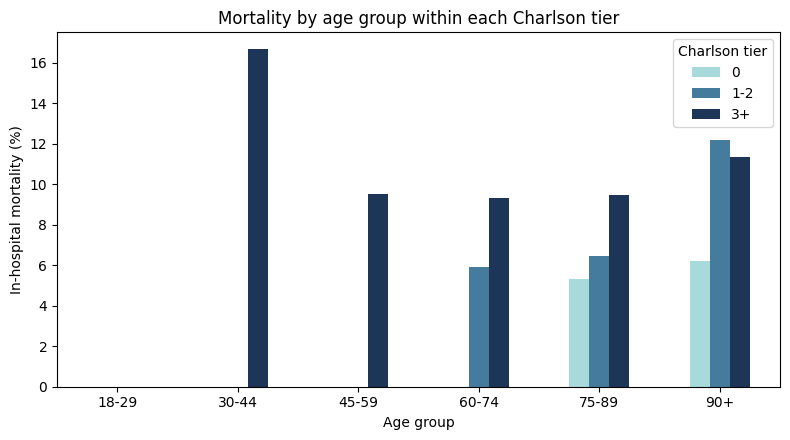

Note: this concerns MORTALITY, not an adjusted change in discharge destination (C1 feedback).


In [32]:
hip['CHARLSON_TIER'] = pd.cut(hip['INDICE_CHARLSON'], bins=[-1, 0, 2, 100], labels=['0', '1-2', '3+'])
tier_mort = pd.crosstab(hip['GRUPO_ETARIO'], hip['CHARLSON_TIER'], values=hip['FALLECIDO'], aggfunc='mean') * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
tier_mort.plot(kind='bar', ax=ax, color=['#a8dadc', '#457b9d', '#1d3557'])
ax.set_ylabel('In-hospital mortality (%)')
ax.set_xlabel('Age group')
ax.set_title('Mortality by age group within each Charlson tier')
ax.legend(title='Charlson tier')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print('Note: this concerns MORTALITY, not an adjusted change in discharge destination (C1 feedback).')

### 7.4 Supporting — mortality by year, and sex comparison

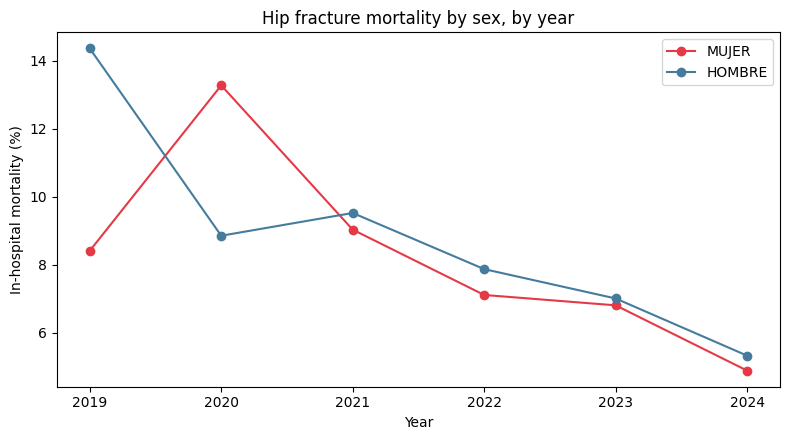

      n_mujer  n_hombre
YEAR                   
2019      428       181
2020      482       192
2021      620       252
2022      914       343
2023      955       371
2024      962       338


In [33]:
mort_year = hip.groupby('YEAR', observed=True).agg(n=('FALLECIDO', 'size'), mortalidad=('FALLECIDO', 'mean'))

mort_year_sex = pd.concat([
    hip.groupby('YEAR', observed=True)['FALLECIDO'].mean().rename('MUJER'),
    hip_m.groupby('YEAR', observed=True)['FALLECIDO'].mean().rename('HOMBRE')
], axis=1) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
mort_year_sex.plot(marker='o', ax=ax, color=['#e63946', '#457b9d'])
ax.set_ylabel('In-hospital mortality (%)')
ax.set_xlabel('Year')
ax.set_title('Hip fracture mortality by sex, by year')
plt.tight_layout()
plt.show()

n_sex = pd.concat([
    hip.groupby('YEAR', observed=True).size().rename('n_mujer'),
    hip_m.groupby('YEAR', observed=True).size().rename('n_hombre')
], axis=1)
print(n_sex)

## 8. Check for data leakage
Intended decision: at **admission**, classify a hip-fracture patient's likely length-of-stay /
mortality risk to plan post-acute capacity. Only information available *at admission* may be
used as an input.

| Risk | Status | Evidence | Action |
|---|---|---|---|
| **Information from the future** | Present | `TIPOALTA`, `FALLECIDO`, `DIAS_ESTANCIA` are only known at/after discharge | Excluded from any future model's inputs; only admission-time fields (age, severity, comorbidity count, admission type) proposed as inputs |
| **An input that gives away the answer** | Present | Using `DIAS_ESTANCIA` to predict a "prolonged stay" label would directly reveal the answer | Target variable (if LOS-based) must be derived from `DIAS_ESTANCIA` and then that column excluded from inputs |
| **Related records crossing the split** | Present | Some `CIP_ENCRIPTADO` values have multiple discharges (not validated as readmissions — see Clean) | Split is time-based (by YEAR), not row-random, which limits but does not fully eliminate this; flagged as a residual risk below |
| **Preparation learned from reserved data** | Not yet applicable in this notebook | No transformation has been fit yet | Addressed directly in Section 10, where the median/encoding is learned on the training split only |

**Open item flagged by C1 feedback, not yet resolved:** whether `IR_29301_SEVERIDAD` and
`INDICE_CHARLSON` are assigned *at admission* or finalized *at/after discharge* is not
documented in the data dictionary available to this team. This must be confirmed before either
field is used as a model input in C2 — until then, treat their availability-at-admission as
**unconfirmed, not assumed**.

In [34]:
# Residual risk check: how many patients have more than one hip-fracture discharge
# in this cohort (relevant to "related records crossing the split")
repeat_patients = hip['CIP_ENCRIPTADO'].value_counts()
print('Patients with >1 hip-fracture discharge in this cohort:', (repeat_patients > 1).sum())

Patients with >1 hip-fracture discharge in this cohort: 25


## 9. Separate the data and demonstrate preparation
No model is trained or scored here (not required for W2) — only the split, validation route,
and one training-only transformation.

**Split choice:** time-based, not random — matches the intended prospective use (classify a
*future* admission), and keeps the full study period's coding/establishment changes from mixing
test-period information into training.

In [35]:
train = hip[hip['YEAR'].isin([2019, 2020, 2021, 2022])].copy()
test  = hip[hip['YEAR'].isin([2023, 2024])].copy()

print('Train rows:', len(train), '| Test rows:', len(test))

# Overlap check: do any patients appear in both train and test?
overlap = set(train['CIP_ENCRIPTADO']) & set(test['CIP_ENCRIPTADO'])
print('Patients appearing in both train and test:', len(overlap))

Train rows: 2444 | Test rows: 1917
Patients appearing in both train and test: 10


**Internal validation route:** a validation subset carved out of the training years (not from
test), used to compare preparation choices before any final evaluation.

In [36]:
train_fit = train[train['YEAR'].isin([2019, 2020, 2021])].copy()
train_val = train[train['YEAR'] == 2022].copy()

print('Train-fit rows:', len(train_fit), '| Train-val rows:', len(train_val), '| Test rows:', len(test))

Train-fit rows: 1530 | Train-val rows: 914 | Test rows: 1917


### 9.1 One training-only transformation
Filling missing `INDICE_CHARLSON` values using the median learned **only** from `train_fit`,
then applying that same fixed value to validation and test without recalculating it there.

In [37]:
charlson_median_train = train_fit['INDICE_CHARLSON'].median()
print('Median Charlson learned from train_fit only:', charlson_median_train)

for d in (train_fit, train_val, test):
    before = d['INDICE_CHARLSON'].isna().sum()
    d['INDICE_CHARLSON'] = d['INDICE_CHARLSON'].fillna(charlson_median_train)
    after = d['INDICE_CHARLSON'].isna().sum()
    print(f'Filled {before - after} missing values; remaining missing: {after}')

# Evidence the transformation applied correctly (same value, not recalculated per split)
print('Any missing INDICE_CHARLSON left in test?', test['INDICE_CHARLSON'].isna().any())

Median Charlson learned from train_fit only: 1.0
Filled 0 missing values; remaining missing: 0
Filled 0 missing values; remaining missing: 0
Filled 0 missing values; remaining missing: 0
Any missing INDICE_CHARLSON left in test? False


**Process diagram (described, matches the two-path structure the brief should show):**
`Training records (train_fit) -> learn median Charlson -> prepared train_fit`
`Validation/test records (train_val, test) + the SAME learned median -> prepared reserved records`
No value was recalculated from `train_val` or `test` — only the single value learned from
`train_fit` was reused.

## 10. AI use and verification
Claude (Anthropic) was used to debug pandas code (execution-order and path issues flagged in C1
feedback), structure this notebook to match the W2 brief, and propose the leakage/split
sections. All numeric outputs above are produced by running this notebook against our own data,
not generated by the AI tool directly. Where Claude's first suggestion was wrong — e.g. an
initial ICD-10 code list for hip fracture (`S72.0`,`S72.1`) that matched zero rows — it was
corrected by inspecting `DIAGNOSTICO1` directly in our own data (see Section 5.1).